In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# EDA

## Step 1: Explore the folders

In [2]:
from pathlib import Path
from collections import Counter

root = Path("/kaggle/input/datasets/mm22f3001706/tumor-dataset")

for d in sorted(p for p in root.rglob("*") if p.is_dir()):
    print(d, len(list(d.glob("*.mat"))), "mat files")

all_files = sorted(root.rglob("*.mat"), key=lambda p: p.stem.isdigit() and int(p.stem) or -1)
print("total .mat files:", len(all_files))
print("examples:", [p.name for p in all_files[:5]])

/kaggle/input/datasets/mm22f3001706/tumor-dataset/brainTumorDataPublic_1-766 766 mat files
/kaggle/input/datasets/mm22f3001706/tumor-dataset/brainTumorDataPublic_1533-2298 766 mat files
/kaggle/input/datasets/mm22f3001706/tumor-dataset/brainTumorDataPublic_2299-3064 766 mat files
/kaggle/input/datasets/mm22f3001706/tumor-dataset/brainTumorDataPublic_767-1532 766 mat files
total .mat files: 3065
examples: ['cvind.mat', '1.mat', '2.mat', '3.mat', '4.mat']


## Look inside one .mat file

top-level keys: ['cjdata']
cjdata/PID                shape=(6, 1) dtype=uint16
cjdata/image              shape=(512, 512) dtype=int16
cjdata/label              shape=(1, 1) dtype=float64
cjdata/tumorBorder        shape=(1, 38) dtype=float64
cjdata/tumorMask          shape=(512, 512) dtype=uint8
label: 1 meningioma
PID: 100360
image: (512, 512) min/max: 0.0 3366.0
mask: (512, 512) unique: [0 1] tumor pixels: 4569 (1.74% of slice)
border points: 19


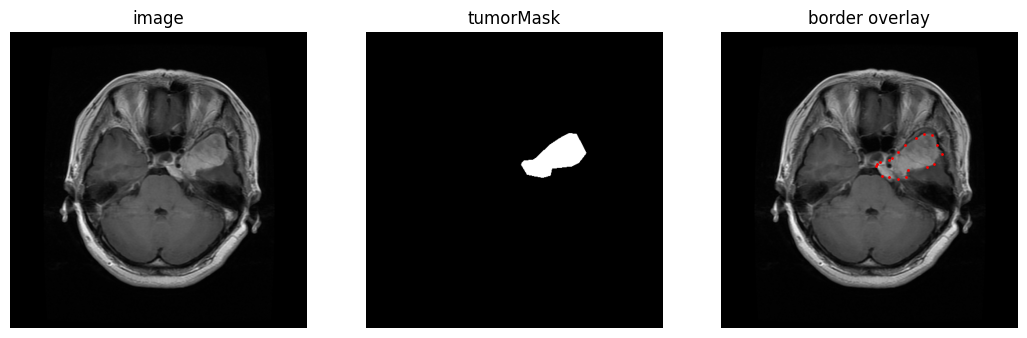

In [3]:
import h5py, numpy as np
import matplotlib.pyplot as plt

f_path = next(p for p in root.rglob("1.mat"))
with h5py.File(f_path, "r") as f:
    print("top-level keys:", list(f.keys()))
    def show(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"{name:25s} shape={obj.shape} dtype={obj.dtype}")
    f.visititems(show)

    d = f["cjdata"]
    image = d["image"][()].T.astype(np.float32)
    mask = d["tumorMask"][()].T.astype(np.uint8)
    label = int(d["label"][()][0][0])
    pid = "".join(chr(c) for c in d["PID"][()].flatten())
    border = d["tumorBorder"][()].flatten()
print("label:", label, {1: "meningioma", 2: "glioma", 3: "pituitary"}[label])
print("PID:", pid)
print("image:", image.shape, "min/max:", image.min(), image.max())
print("mask:", mask.shape, "unique:", np.unique(mask), "tumor pixels:", mask.sum(), f"({100*mask.mean():.2f}% of slice)")
print("border points:", len(border) // 2)

# normalize to 0-255 exactly like the README's MATLAB code
img8 = (255*(image - image.min()) / (image.max() - image.min())).astype(np.uint8)

bx, by = border[0::2], border[1::2]
fig, ax = plt.subplots(1,3, figsize=(13, 4))
ax[0].imshow(img8, cmap="gray");        ax[0].set_title("image")
ax[1].imshow(mask, cmap="gray");        ax[1].set_title("tumorMask")
ax[2].imshow(img8, cmap="gray");        ax[2].plot(bx, by, "r.", ms=2); ax[2].set_title("border overlay")
for a in ax: a.axis("off")
plt.show()


## A metadata table

In [4]:
rows = []
for p in all_files[1:]:
    # print(p)
    with h5py.File(p, "r") as f:
        d = f["cjdata"]
        img = d["image"]
        rows.append({
            "file": p.name,
            "id": int(p.stem),
            "label": int(d["label"][()][0][0]),
            "pid": "".join(chr(c) for c in d["PID"][()].flatten()),
            "h": img.shape[1], "w": img.shape[0],
            "dtype": str(img.dtype),
            "tumor_frac": float(d["tumorMask"][()].mean()),
        })
df = pd.DataFrame(rows)
df.to_csv("metadata.csv", index=False)

print(df.label.value_counts().sort_index())

label
1     708
2    1426
3     930
Name: count, dtype: int64


In [5]:
df

,file,id,label,pid,h,w,dtype,tumor_frac
0,1.mat,1,1,100360,512,512,int16,0.017429
1,2.mat,2,1,100360,512,512,int16,0.032921
2,3.mat,3,1,100360,512,512,int16,0.040096
3,4.mat,4,1,100360,512,512,int16,0.033939
4,5.mat,5,1,100360,512,512,int16,0.042915
...,...,...,...,...,...,...,...,...
3059,3060.mat,3060,2,MR029209I,512,512,int16,0.030277
3060,3061.mat,3061,2,MR029209I,512,512,int16,0.017307
3061,3062.mat,3062,2,MR029209I,512,512,int16,0.002335
3062,3063.mat,3063,1,95969,512,512,int16,0.006447


# Config

In [6]:
from pathlib import Path
SEED = 42
IMG_SIZE = 256
TEST_FRAC = 0.15
VAL_FRAC = 0.15
META_CSV = Path("/kaggle/working/metadata.csv")
OUT_DIR = Path("/kaggle/working/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)

## Sanity Checks

In [7]:
df = pd.read_csv(META_CSV)
df["label"].value_counts()

label
2    1426
3     930
1     708
Name: count, dtype: int64

In [8]:
# labels in the raw data are 1,2,3. PyTorch's CrossEntropyLoss excepts 0,1,2.
df["label0"] = df["label"] - 1
print("slices:", len(df), "| patients:", df.pid.nunique())

slices: 3064 | patients: 233


In [9]:
# Check 1: does each patient have exactly ONE tumor type?
# If yes, we can say "stratified by class" meaningfully at patient level.
labels_per_patient = df.groupby("pid")["label"].nunique()
print("patients with >1 label:", (labels_per_patient > 1).sum())


patients with >1 label: 0


In [10]:
# Check 2: slices per patient. Uneven counts mean a patient-level split
# will not give exact 70/15/15 slice percentages 
print(df.groupby("pid").size().describe())

count    233.000000
mean      13.150215
std        7.655779
min        1.000000
25%        7.000000
50%       13.000000
75%       18.000000
max       38.000000
dtype: float64


# Patient-level split

In [11]:
from sklearn.model_selection import GroupShuffleSplit

# Split 1: crave out the TEST set
gss = GroupShuffleSplit(n_splits=1, test_size=TEST_FRAC, random_state=SEED)
trainval_idx, test_idx = next(gss.split(df, groups=df["pid"]))

trainval = df.iloc[trainval_idx]
test = df.iloc[test_idx]

In [12]:
# Split 2: from what remains, crave out VALIDATION
# VAL_FRAC is a fraction of the whole dataset, so rescale it to the remaining part.
val_rel = VAL_FRAC / (1 - TEST_FRAC)
gss2 = GroupShuffleSplit(n_splits=1, test_size=val_rel, random_state=SEED)
train_idx, val_idx = next(gss2.split(trainval, groups=trainval["pid"]))

df["split"] = ""
df.loc[trainval.index[train_idx], "split"] = "train"
df.loc[trainval.index[val_idx], "split"] = "val"
df.loc[test.index, "split"] = "test"


In [17]:
# Safety check: no patient may appear in two splits
pid_sets = {s: set(df[df.split == s].pid) for s in ["train", "val", "test"]}
assert not (pid_sets["train"] & pid_sets["val"]), "LEAK: train/val share patients"
assert not (pid_sets["train"] & pid_sets["test"]), "LEAK: train/test share patients"
assert not (pid_sets["val"] & pid_sets["test"]), "LEAK: val/test share patients"
print("No patient overlap between splits")

No patient overlap between splits


In [26]:
# Report: how balanced are the splits?
summary = df.groupby("split").agg(slices=("id", "size"), patients=("pid", "nunique"))
print(summary)
print(pd.crosstab(df["split"], df["label"], normalize="index").round(3))

       slices  patients
split                  
test      471        35
train    2144       163
val       449        35
label      1      2      3
split                     
test   0.153  0.537  0.310
train  0.259  0.451  0.289
val    0.178  0.457  0.365


# Preprocessing functions

In [27]:
import h5py, cv2

def load_slice(path):
    """Read one .mat file -> (image float32, mast uint8). MATLAB is column-major, so transpose."""
    with h5py.File(path, "r") as f:
        d = f["cjdata"]
        image = d["image"][()].T.astype(np.float32)
        mask = d["tumorMask"][()].T.astype(np.unit8)
    return image, mask

def preprocess(image, mask, size=IMG_SIZE):
    """
    Turn one raw slice into a compact (unit8 image, unit8 mask) pair.
    1. Min-max normalize intensities to 0-255. Raw MRI intensities differ between
       scans, so this puts every slice on the same scale (same as the dataset
       authors' MATLAB coversion code).
    2. Resize the image with INTER_AREA (best for shrinking: avoids aliasing).
    3. Resize the mask with INTER_NEAREST so it stays strictly binary (0/1).
       Smooth interpolation would create in-between values at the tumor edge.
    """
    lo, hi = float(image.min()), float(image.max())
    if hi == lo:
        img8 = np.zeros_like(image, dtype=np.uint8)
    else:
        img8 = ((image - lo) / (hi - lo) * 255).astype(np.uint8)
    img_r = cv2.resize(img8, (size, size), interpolation=cv2.INTER_AREA)
    mask_r = cv2.resize(mask, (size, size), interpolation=cv2.INTER_NEAREST)
    return img_r, mask_r